<a href="https://colab.research.google.com/github/Prajwalhegde30/Admissions/blob/main/Sentiment_Analysis_Customer_Reviews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment Analysis of Customer Product Reviews Using Machine Learning

## 1. Introduction

**Problem:** Product reviews contain opinions that are difficult to summarize manually. This notebook classifies each English Amazon review as **negative**, **neutral**, or **positive**.

**Objective:** Load a genuine, labeled review dataset, apply a pre-trained three-class model, compare predictions with held-out rating-derived labels, and try the model on a new review.

**Sentiment analysis** uses natural language processing (NLP) to identify the opinion expressed in text. The chosen model has a three-class output head, so neutral is an actual model class rather than a rule added after binary classification.

This is a technical implementation for the ABL classroom demonstration, not the academic report.

## 2. Environment setup

In Colab, choose **Runtime → Run all**. The model weights and a small test split are downloaded on the first run. A GPU is optional; inference also works on CPU.

In [1]:
%pip install -q "datasets>=3.0,<5.0" "transformers>=4.44,<5.0" seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 612.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 32.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os
os.environ["USE_TF"] = "0"  # Use the PyTorch runtime; TensorFlow is not needed here.
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)
from transformers import AutoModelForSequenceClassification, AutoTokenizer

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")

PyTorch: 2.11.0+cpu
Device: cpu


## 3. Dataset loading

We use the English subset of **The Multilingual Amazon Reviews Corpus (MARC)**. It contains review text (`review_body`) and a 1–5 star rating (`stars`). The Hugging Face data-files mirror provides the same named corpus in standard data files and preserves the official split structure; this avoids a deprecated dataset-loading script.

- Original dataset: [Hugging Face `amazon_reviews_multi`](https://huggingface.co/datasets/amazon_reviews_multi)
- Data-files mirror and schema: [goosmanlei/amazon_reviews_multi](https://huggingface.co/datasets/goosmanlei/amazon_reviews_multi)
- Dataset paper: [The Multilingual Amazon Reviews Corpus (MARC)](https://arxiv.org/abs/2010.02573)

We only use the existing **test** split for model evaluation. Star ratings are converted to sentiment labels in the next section; they are useful ground truth but are not hand-annotated emotion labels.

In [3]:
TEST_FILE = "hf://datasets/goosmanlei/amazon_reviews_multi/en/test.jsonl.gz"

# Load only the held-out test file, not the 200,000-row training file.
review_dataset = load_dataset("json", data_files={"test": TEST_FILE})
print(review_dataset)
print("Available splits:", list(review_dataset.keys()))
print("Test split columns:", review_dataset["test"].column_names)

test_df = review_dataset["test"].to_pandas()
print("\nFirst five rows:")
display(test_df.head())
print("\nDataset dimensions:", test_df.shape)
print("\nColumn names:", test_df.columns.tolist())
print("\nData types:\n", test_df.dtypes)
print("\nMissing values:\n", test_df.isna().sum())
print("\nDuplicate review IDs:", test_df["review_id"].duplicated().sum())
print("Duplicate review texts:", test_df["review_body"].duplicated().sum())
print("\nStar rating counts:\n", test_df["stars"].value_counts().sort_index())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


en/test.jsonl.gz:   0%|          | 0.00/536k [00:00<?, ?B/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
})
Available splits: ['test']
Test split columns: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category']

First five rows:


,review_id,product_id,reviewer_id,stars,review_body,review_title,language,product_category
0,en_0199937,product_en_0902516,reviewer_en_0097389,1,"These are AWFUL. They are see through, the fab...",Don’t waste your time!,en,apparel
1,en_0863335,product_en_0348072,reviewer_en_0601537,1,I bought 4 and NONE of them worked. Yes I used...,One Star,en,other
2,en_0565010,product_en_0356154,reviewer_en_0970351,1,On first use it didn't heat up and now it does...,Totally useless,en,other
3,en_0963290,product_en_0583322,reviewer_en_0216125,1,You want an HONEST answer? I just returned fro...,Gold filled earrings,en,jewelry
4,en_0238156,product_en_0487636,reviewer_en_0514203,1,The glue works fine but the container is impos...,Poor container,en,industrial_supplies



Dataset dimensions: (5000, 8)

Column names: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category']

Data types:
 review_id           object
product_id          object
reviewer_id         object
stars                int64
review_body         object
review_title        object
language            object
product_category    object
dtype: object

Missing values:
 review_id           0
product_id          0
reviewer_id         0
stars               0
review_body         0
review_title        1
language            0
product_category    0
dtype: int64

Duplicate review IDs: 0
Duplicate review texts: 0

Star rating counts:
 stars
1    1000
2    1000
3    1000
4    1000
5    1000
Name: count, dtype: int64


## 4. Data preprocessing

For this model, we preserve the natural wording, including negations such as “not good.” Only missing/blank reviews, invalid ratings, and duplicate review records are removed. The label mapping is **1–2 stars → negative, 3 stars → neutral, and 4–5 stars → positive**. These are rating-derived labels, so a customer's rating and the text's expressed sentiment can sometimes disagree.

In [4]:
STAR_TO_SENTIMENT = {
    1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"
}
SENTIMENT_LABELS = ["negative", "neutral", "positive"]

clean_df = test_df.copy()
clean_df = clean_df.dropna(subset=["review_body", "stars"])
clean_df["review_body"] = clean_df["review_body"].astype(str).str.strip()
clean_df["stars"] = pd.to_numeric(clean_df["stars"], errors="coerce")
clean_df = clean_df.dropna(subset=["stars"])
clean_df = clean_df[clean_df["stars"].isin(STAR_TO_SENTIMENT)]
clean_df = clean_df[clean_df["review_body"].str.len() > 0]
clean_df = clean_df.drop_duplicates(subset=["review_id"], keep="first")
clean_df = clean_df.drop_duplicates(subset=["review_body"], keep="first").copy()
clean_df["actual_sentiment"] = clean_df["stars"].astype(int).map(STAR_TO_SENTIMENT)

print("Clean rows:", len(clean_df))
print("Available sentiment classes:", sorted(clean_df["actual_sentiment"].unique()))
print("Sentiment counts:\n", clean_df["actual_sentiment"].value_counts().reindex(SENTIMENT_LABELS))
assert set(clean_df["actual_sentiment"].unique()) == set(SENTIMENT_LABELS), "Expected all three classes in the test split."

Clean rows: 5000
Available sentiment classes: ['negative', 'neutral', 'positive']
Sentiment counts:
 actual_sentiment
negative    2000
neutral     1000
positive    2000
Name: count, dtype: int64


## 5. Exploratory data analysis

The first chart shows the class distribution after rating mapping and cleaning. The second shows review length in words; the distribution can be skewed by a smaller number of long reviews.

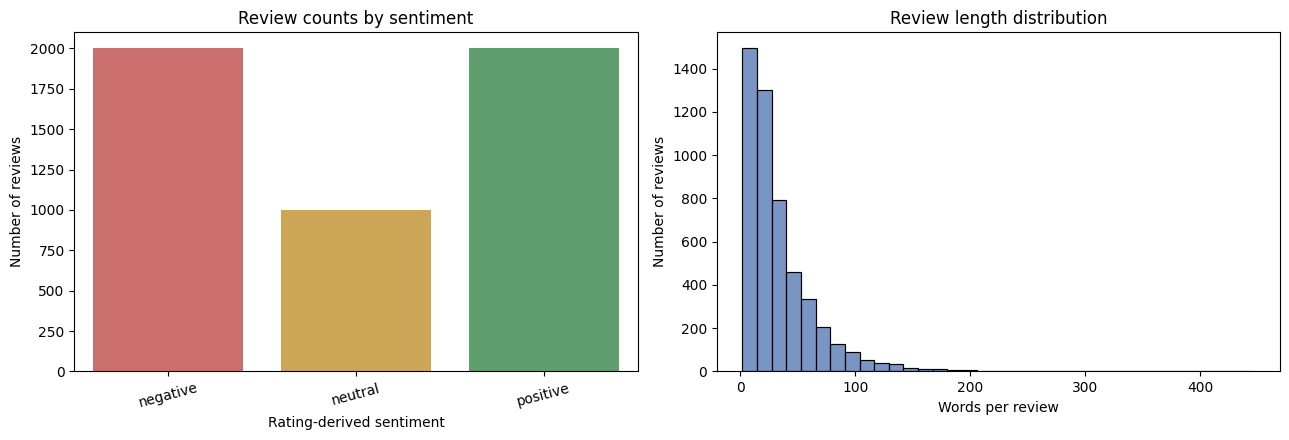

Review word-count summary:
 count    5000.0
mean       33.9
std        32.8
min         2.0
25%        12.0
50%        24.0
75%        44.0
max       447.0
Name: review_word_count, dtype: float64


In [5]:
clean_df["review_word_count"] = clean_df["review_body"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
class_counts = clean_df["actual_sentiment"].value_counts().reindex(SENTIMENT_LABELS, fill_value=0)
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette={"negative": "#d95f5f", "neutral": "#e0ac45", "positive": "#55a868"}, legend=False, ax=axes[0])
axes[0].set_title("Review counts by sentiment")
axes[0].set_xlabel("Rating-derived sentiment")
axes[0].set_ylabel("Number of reviews")
axes[0].tick_params(axis="x", rotation=15)
sns.histplot(data=clean_df, x="review_word_count", bins=35, color="#4c72b0", ax=axes[1])
axes[1].set_title("Review length distribution")
axes[1].set_xlabel("Words per review")
axes[1].set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

print("Review word-count summary:\n", clean_df["review_word_count"].describe().round(1))

## 6. Model implementation

We use [`lxyuan/distilbert-base-multilingual-cased-sentiments-student`](https://huggingface.co/lxyuan/distilbert-base-multilingual-cased-sentiments-student), a pre-trained, distilled DistilBERT model. Its published configuration has three outputs: positive, neutral, and negative. It is smaller than a full-size BERT model and can run on a standard Colab CPU, though a GPU can make batch evaluation faster.

The classifier was trained through multilingual sentiment distillation rather than specifically on this Amazon test set. The notebook checks the model's actual labels and uses inference only; it does not fine-tune the model on evaluation data.

In [6]:
MODEL_ID = "lxyuan/distilbert-base-multilingual-cased-sentiments-student"

# Load once, then reuse for both evaluation and interactive predictions.
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID).to(DEVICE)
model.eval()

id_to_label = {int(key): value.lower() for key, value in model.config.id2label.items()}
print("Model output labels:", id_to_label)
assert set(id_to_label.values()) == set(SENTIMENT_LABELS), "Model does not expose the expected three sentiment labels."

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

Model output labels: {0: 'positive', 1: 'neutral', 2: 'negative'}


In [7]:
def predict_reviews(review_texts, batch_size=16, max_length=256):
    """Return one label and a probability dictionary for each non-empty review."""
    if isinstance(review_texts, str):
        review_texts = [review_texts]
    if not isinstance(review_texts, (list, tuple)):
        return [{"sentiment": "Invalid input", "confidence": None, "probabilities": {}}]

    results = []
    valid_positions = []
    valid_texts = []
    for position, text in enumerate(review_texts):
        if not isinstance(text, str) or not text.strip():
            results.append({"sentiment": "Invalid input", "confidence": None, "probabilities": {}})
        else:
            results.append(None)
            valid_positions.append(position)
            valid_texts.append(text.strip())

    for start in range(0, len(valid_texts), batch_size):
        batch_texts = valid_texts[start:start + batch_size]
        encoded = tokenizer(
            batch_texts, padding=True, truncation=True, max_length=max_length,
            return_tensors="pt"
        ).to(DEVICE)
        with torch.inference_mode():
            probabilities = torch.softmax(model(**encoded).logits, dim=-1).cpu().numpy()

        for offset, row in enumerate(probabilities):
            probability_by_label = {id_to_label[i]: float(row[i]) for i in range(len(row))}
            predicted_label = max(probability_by_label, key=probability_by_label.get)
            original_position = valid_positions[start + offset]
            results[original_position] = {
                "sentiment": predicted_label,
                "confidence": probability_by_label[predicted_label],
                "probabilities": probability_by_label,
            }
    return results

# Graceful behavior for empty or invalid inputs:
print("Blank input check:", predict_reviews("   "))
print("Invalid type check:", predict_reviews(None))

Blank input check: [{'sentiment': 'Invalid input', 'confidence': None, 'probabilities': {}}]
Invalid type check: [{'sentiment': 'Invalid input', 'confidence': None, 'probabilities': {}}]


## 7. Sentiment classification on real product reviews

The predictions below come from actual reviews in the held-out dataset test split. Nothing is hardcoded; each predicted label is produced by the loaded model.

In [8]:
# Use a reproducible, balanced sample from the held-out test split.
# Balanced sampling makes class-level comparisons easier to discuss in a short demo.
sampled_parts = []
per_class = min(200, int(clean_df["actual_sentiment"].value_counts().min()))
for sentiment in SENTIMENT_LABELS:
    sampled_parts.append(
        clean_df[clean_df["actual_sentiment"] == sentiment].sample(
            n=per_class, random_state=RANDOM_SEED
        )
    )
evaluation_df = pd.concat(sampled_parts).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
print(f"Held-out evaluation examples: {len(evaluation_df)} ({per_class} per class)")

# Run model inference once and reuse the results in later sections.
evaluation_results = predict_reviews(evaluation_df["review_body"].tolist(), batch_size=16)
evaluation_df["predicted_sentiment"] = [item["sentiment"] for item in evaluation_results]
evaluation_df["confidence"] = [item["confidence"] for item in evaluation_results]

sample_rows = []
for sentiment in SENTIMENT_LABELS:
    matching = evaluation_df[evaluation_df["actual_sentiment"] == sentiment].head(2)
    sample_rows.append(matching)
sample_predictions = pd.concat(sample_rows)[["review_body", "actual_sentiment", "predicted_sentiment"]]
sample_predictions = sample_predictions.rename(columns={
    "review_body": "Review text", "actual_sentiment": "Actual sentiment",
    "predicted_sentiment": "Predicted sentiment"
})
display(sample_predictions.reset_index(drop=True))

Held-out evaluation examples: 600 (200 per class)


,Review text,Actual sentiment,Predicted sentiment
0,It will not turn on. It was a gift and the per...,negative,negative
1,The teapot came with many visible scratches on...,negative,negative
2,Looks and fits fine BUT the yarn is itchy.. sh...,neutral,negative
3,Due to the size of the computer part of the br...,neutral,negative
4,Very breathable and easy to put on.,positive,positive
5,Outstanding product exceeds my expectations....,positive,positive


## 8. Model evaluation

Metrics compare the model's predictions with rating-derived labels from the separate Amazon test split. Macro precision, recall, and F1 give each of the three classes equal weight. Accuracy alone can hide poor performance on a less common class; the class-count chart and confusion matrix help show this. Because we sample equally from the available classes, the evaluation subset is balanced.

,Metric,Score
0,Accuracy,0.5317
1,Macro precision,0.4877
2,Macro recall,0.5317
3,Macro F1-score,0.4805


Classification report (rating-derived reference labels):
              precision    recall  f1-score   support

    negative     0.5385    0.6650    0.5951       200
     neutral     0.3582    0.1200    0.1798       200
    positive     0.5664    0.8100    0.6667       200

    accuracy                         0.5317       600
   macro avg     0.4877    0.5317    0.4805       600
weighted avg     0.4877    0.5317    0.4805       600



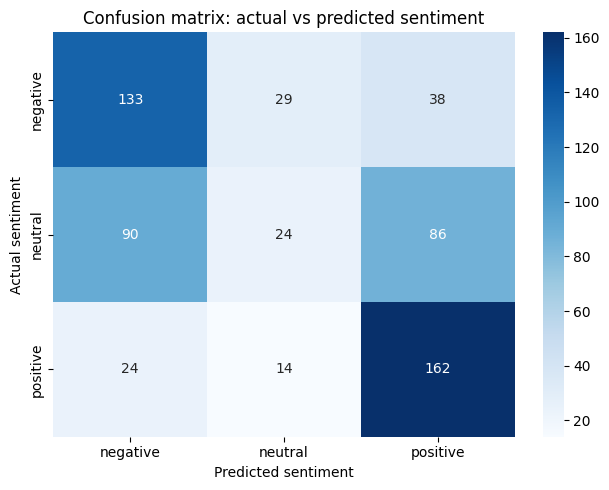

Confusion matrix shape: (3, 3)
Predicted labels: ['negative', 'neutral', 'positive']


In [9]:
y_true = evaluation_df["actual_sentiment"]
y_pred = evaluation_df["predicted_sentiment"]

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro precision": precision_score(y_true, y_pred, labels=SENTIMENT_LABELS, average="macro", zero_division=0),
    "Macro recall": recall_score(y_true, y_pred, labels=SENTIMENT_LABELS, average="macro", zero_division=0),
    "Macro F1-score": f1_score(y_true, y_pred, labels=SENTIMENT_LABELS, average="macro", zero_division=0),
}
metrics_df = pd.DataFrame({"Metric": metrics.keys(), "Score": metrics.values()})
display(metrics_df.style.format({"Score": "{:.4f}"}))

print("Classification report (rating-derived reference labels):")
print(classification_report(y_true, y_pred, labels=SENTIMENT_LABELS, target_names=SENTIMENT_LABELS, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=SENTIMENT_LABELS)
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=SENTIMENT_LABELS, yticklabels=SENTIMENT_LABELS)
plt.title("Confusion matrix: actual vs predicted sentiment")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.tight_layout()
plt.show()

assert cm.shape == (3, 3)
assert set(y_pred.unique()).issubset(set(SENTIMENT_LABELS))
print("Confusion matrix shape:", cm.shape)
print("Predicted labels:", sorted(y_pred.unique()))

## 9. Interactive review predictor

Run this cell in Colab and type a review when prompted. The model reports its top label and the softmax score for each class. These scores indicate the model's relative confidence; they are not guarantees of correctness or calibrated probabilities.

In [14]:
def interactive_review_demo():
    review = input("Enter a customer product review (or press Enter to skip): ").strip()
    if not review:
        print("No review entered. Re-run this cell when you are ready to try a review.")
        return

    result = predict_reviews(review)[0]
    print("\nReview:", review)
    print("Predicted sentiment:", result["sentiment"])
    if result["confidence"] is not None:
        print(f"Top-class score: {result['confidence']:.1%}")
        print("Class scores:")
        for label in SENTIMENT_LABELS:
            print(f"  {label.title():<9} {result['probabilities'][label]:.1%}")
    print("\nWarning: this is a model prediction and may be incorrect.")

interactive_review_demo()

Enter a customer product review (or press Enter to skip): The product is average and does what it claims.

Review: The product is average and does what it claims.
Predicted sentiment: neutral
Top-class score: 37.9%
Class scores:
  Negative  30.2%
  Neutral   37.9%
  Positive  31.9%



## 10. End-to-end demonstration

All components are already loaded and evaluated above, so this section reuses the results instead of downloading or calculating them again. Review the sample prediction table, evaluation scores, and visualizations above, then run the interactive predictor cell to classify a new review.

In [11]:
print("Dataset rows used for evaluation:", len(evaluation_df))
print("Model:", MODEL_ID)
print("Classes:", ", ".join(SENTIMENT_LABELS))
print("Accuracy: {:.4f} | Macro F1: {:.4f}".format(metrics["Accuracy"], metrics["Macro F1-score"]))
display(sample_predictions.reset_index(drop=True))

Dataset rows used for evaluation: 600
Model: lxyuan/distilbert-base-multilingual-cased-sentiments-student
Classes: negative, neutral, positive
Accuracy: 0.5317 | Macro F1: 0.4805


,Review text,Actual sentiment,Predicted sentiment
0,It will not turn on. It was a gift and the per...,negative,negative
1,The teapot came with many visible scratches on...,negative,negative
2,Looks and fits fine BUT the yarn is itchy.. sh...,neutral,negative
3,Due to the size of the computer part of the br...,neutral,negative
4,Very breathable and easy to put on.,positive,positive
5,Outstanding product exceeds my expectations....,positive,positive


## 11. Technical summary

- **Dataset:** English Amazon Reviews Multi (MARC), using its held-out test split.
- **Model:** Pre-trained `lxyuan/distilbert-base-multilingual-cased-sentiments-student` with native negative, neutral, and positive outputs.
- **Reference labels:** 1–2 stars negative, 3 stars neutral, 4–5 stars positive. These are derived from customer ratings.
- **Evaluation subset:** A reproducible, balanced sample (up to 200 examples per class) from the test split. No model training or fine-tuning occurs in this notebook.
- **Metrics:** Generated from actual model predictions and displayed in Section 8 when the notebook is executed. They are intentionally not written as fixed numbers in advance.
- **Limitations:** Ratings can disagree with the text; the model was not fine-tuned specifically for Amazon products; long text is truncated to 256 tokens; irony, mixed opinions, domain language, and implicit sentiment can be difficult. The model's score is not a guarantee of correctness.

In [12]:
print("Dataset: English Amazon Reviews Multi (MARC), held-out test split")
print("Model:", MODEL_ID)
print("Sentiment classes:", ", ".join(SENTIMENT_LABELS))
print("Evaluation examples:", len(evaluation_df), "(balanced across the three classes)")
for metric_name, metric_value in metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")
print("\nInterpretation: scores are measured against star-rating-derived labels. The neutral class is harder to identify in this evaluation; consult its recall and the confusion matrix above.")
print("Limitations: ratings can disagree with text; the model is general-purpose, long reviews are truncated to 256 tokens, and irony or mixed opinions can be misclassified.")

Dataset: English Amazon Reviews Multi (MARC), held-out test split
Model: lxyuan/distilbert-base-multilingual-cased-sentiments-student
Sentiment classes: negative, neutral, positive
Evaluation examples: 600 (balanced across the three classes)
Accuracy: 0.5317
Macro precision: 0.4877
Macro recall: 0.5317
Macro F1-score: 0.4805

Interpretation: scores are measured against star-rating-derived labels. The neutral class is harder to identify in this evaluation; consult its recall and the confusion matrix above.
Limitations: ratings can disagree with text; the model is general-purpose, long reviews are truncated to 256 tokens, and irony or mixed opinions can be misclassified.
